### Phase 2: OLS Baseline
This section introduces an ordinary least squares baseline which allows for manual calculation of the hedge ratio $\beta$ and the intercept ($\alpha$). By looking at these parameters across multiple time windows, we aim to observe and evaluate the  relationship between assets.

All regressions here run on log prices. Log differences are returns so $\beta$ is a portfolio weight (dollars of X per dollar of Y) rather than a share ratio. This matters once the spread gets traded because a share-ratio applied to returns makes a different portfolio than what was fitted.

Both baselines are evaluated on a held-out test set. The static model is fit on the first 20% of the sample and then frozen. 

### Cell 1: Static OLS Hedge Ratio
This cell begins with the same framework from [01_coint_tests.ipynb](01_coint_tests.ipynb) - importing all asset data from [data.py](models/data.py), creating testing pairs, and setting up time windows. To create the OLS baseline and understand both the hedge ratio ${\beta}$ and intercept ${\alpha}$, we create a function in [ols.py](models/ols.py) and run $${\beta}_{\text{matrix}} = ({{X^T}{X}}^{-1})~{X^T}{y}$$
which results in both ${\beta}$ and ${\alpha}$. 

<small>

- The normal equations are written with an inverse but solved using `np.linalg.solve`

- This process runs through every pair for every window.

</small>



In [13]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from models.data import PAIRS, load_panel
from models.ols import fit_static_ols

# Create function to get betas and z-scores for any pair of assets
def calc_rolling_signals(lx, ly, window):
    records = []
    for i in range(window, len(ly) + 1):
        xs = lx.iloc[i - window : i]
        ys = ly.iloc[i - window : i]

        beta, alpha = fit_static_ols(xs, ys)
        spread = ys - beta * xs - alpha
        z = (spread.iloc[-1] - spread.mean()) / spread.std()

        records.append({
            "date":  ys.index[-1],
            "beta":  beta,
            "alpha": alpha,
            "spread": spread.iloc[-1],
            "z":     z,
        })
    return pd.DataFrame(records).set_index("date")

prices, log_prices = load_panel()

A, B = "V", "MA"
lx, ly = log_prices[A], log_prices[B]

TRAIN_FRAC = 0.20
SPLIT = int(len(log_prices) * TRAIN_FRAC)

print(f"Train: {log_prices.index[0].date()} → {log_prices.index[SPLIT-1].date()}  ({SPLIT} rows)")
print(f"Test:  {log_prices.index[SPLIT].date()} → {log_prices.index[-1].date()}  ({len(log_prices)-SPLIT} rows)")

windows = {252: "1Y", 504: "2Y", 756: "3Y", 1260: "5Y", None: "10Y"}
rows = []
for days, label in windows.items():
    sl = log_prices if days is None else log_prices.iloc[-days:]
    for a, b in PAIRS:
        beta, alpha = fit_static_ols(sl[a], sl[b])
        rows.append({"window": label, "pair": f"{a}/{b}", "beta": beta})

beta_table = (pd.DataFrame(rows)
              .pivot(index="pair", columns="window", values="beta")[["1Y","2Y","3Y","5Y","10Y"]])
print("\nStatic hedge ratio (log-price beta) by window:")
print(beta_table.round(4).to_string())

Train: 2016-07-22 → 2018-07-19  (502 rows)
Test:  2018-07-20 → 2026-07-21  (2010 rows)

Static hedge ratio (log-price beta) by window:
window         1Y      2Y      3Y      5Y     10Y
pair                                             
EEM/EMB    0.1915  0.3207  0.4421  0.5428  0.4389
EFA/VEA    1.3400  1.1872  1.1208  1.0445  1.0449
EWA/EWC    1.2170  1.7407  1.6253  1.4691  1.3370
GDX/GDXJ   1.1184  1.0916  1.0902  1.0626  0.9231
GLD/IAU    1.0016  1.0033  1.0040  1.0059  1.0107
GLD/SLV    2.1795  1.6020  1.3057  1.1692  1.0423
HD/LOW     0.6732  0.7502  0.8152  0.8629  1.2017
IWM/IWO    0.9273  0.9928  1.0341  1.0803  1.0072
KO/PEP     0.3263  0.0677 -0.1856 -0.0351  0.8311
LQD/HYG    0.8976  1.1995  1.3293  1.0458  0.9989
MSFT/AAPL -0.4457 -0.0499  0.6028  0.8036  1.0604
SPY/IVV    1.0024  1.0038  1.0039  1.0044  1.0041
TLT/IEF    0.4948  0.3719  0.6697  0.2912  0.3467
USO/BNO    0.9341  0.9515  0.9531  1.0099  0.5306
V/MA       0.9811  0.6827  0.8758  0.9721  1.1738
XLE/XOP    0.98

### Cell 2: Rolling Z-score

In statistics and data science, Z-scores are a crucial tool used to standardize data and provide a universal understanding of how many standard deviations a data point sits away from its mean.

---

##### The Problem: Static Calculations
When using a fixed hedge ratio and intercept to calculate a static Z-score across a full dataset, a massive structural flaw arises: Lookahead Bias. This occurs when future information is fed into past data, influencing trading decisions and creating fake profitability.

---

##### The Solution: Rolling Slices
Rolling slices remove lookahead from the rolling estimator: each z-score uses only data from the window before it. The static baseline needs a train/test split, so its $\beta$, $\alpha$, and $\sigma$ are estimated once on early data and frozen before any trade is placed. Both are applied in this notebook.

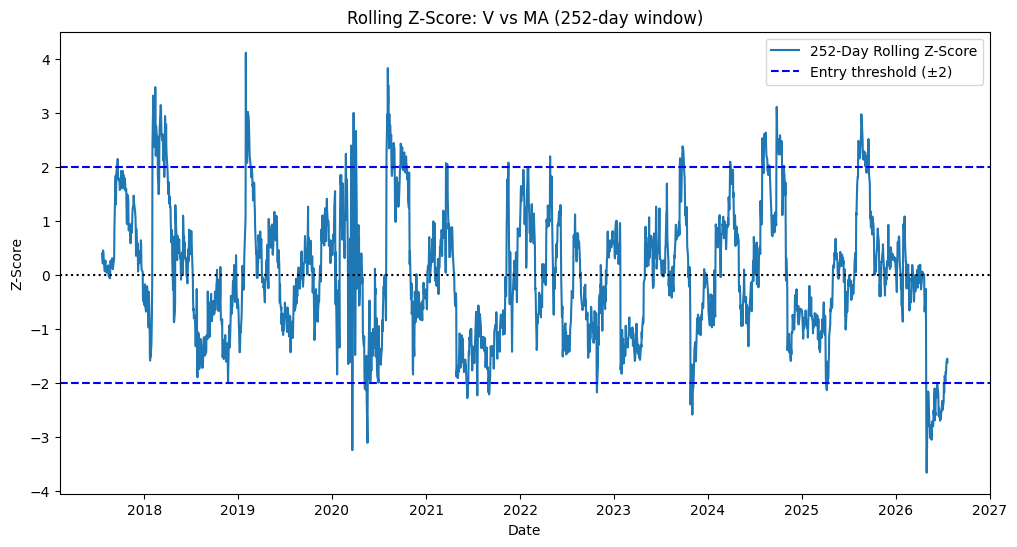

In [14]:
z_252 = calc_rolling_signals(lx, ly, 252)

plt.figure(figsize=(12, 6))
plt.plot(z_252.index, z_252["z"], label="252-Day Rolling Z-Score")
plt.axhline(0, color="black", linestyle=":")
plt.axhline(2, color="blue", linestyle="--", label="Entry threshold (±2)")
plt.axhline(-2, color="blue", linestyle="--")
plt.title(f"Rolling Z-Score: {A} vs {B} (252-day window)")
plt.xlabel("Date"); plt.ylabel("Z-Score"); plt.legend(); plt.show()

### Cell 3: Calculate rolling scores
Fast vs. slow signal tracking highlights a core tradeoff between responsiveness and stability.
 
 ---

##### 20-Day Window
 - Key Characteristics: 
    - Very sensitive, short memory, $\mu$ and $\sigma$ change rapidly every day
    - Would cross trading entry and exit thresholds many times (mostly due to market noise)

##### 120-Day Window
 - Key Characteristics: 
    - Longer memory, much smoother than 20-day counterpart
    - Only crosses thresholds when there are major divergences

---

Both rolling z-scores are overlayed to visually inspect the sensitivity tradeoff

Each row is dated at the last day of the window used to produce it - `ys.index[-1]`, read directly off the slice. The slice `[i-window : i]` is half-open, so it contains data through position i-1, not i. Computing the position and the date separately is how an estimate ends up labeled a day away from the data it contains; reading the date off the data makes that impossible.


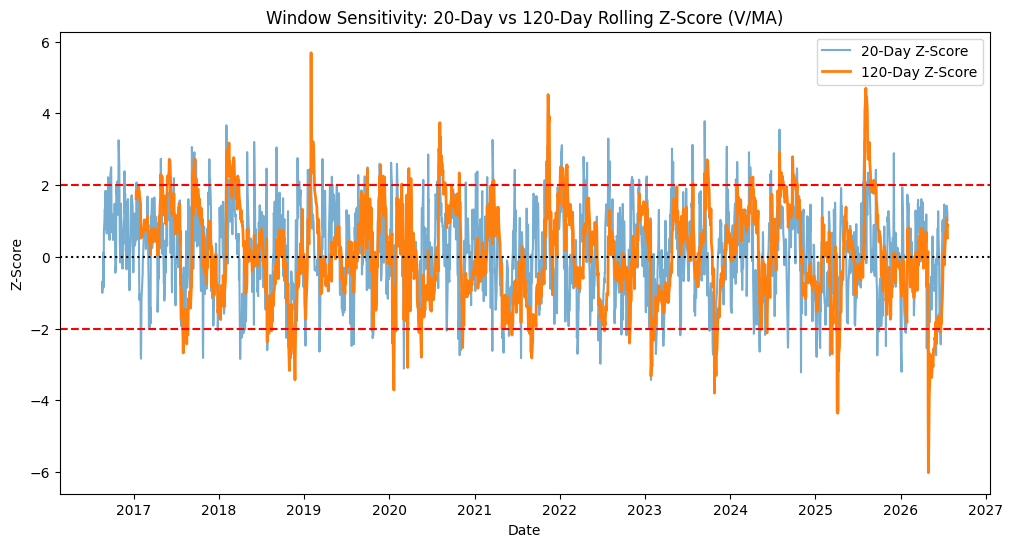

In [15]:
roll_20  = calc_rolling_signals(lx, ly, 20)
roll_120 = calc_rolling_signals(lx, ly, 120)

plt.figure(figsize=(12, 6))
plt.plot(roll_20.index,  roll_20["z"],  label="20-Day Z-Score", alpha=0.6)
plt.plot(roll_120.index, roll_120["z"], label="120-Day Z-Score", linewidth=2)
plt.axhline(0, color="black", linestyle=":")
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="red", linestyle="--")
plt.title(f"Window Sensitivity: 20-Day vs 120-Day Rolling Z-Score ({A}/{B})")
plt.xlabel("Date"); plt.ylabel("Z-Score"); plt.legend(); plt.show()

### Cell 4: Beta Instability

A fundamental assumption of pairs trading is that the hedge ratio $\beta$ remains constant over the testing period. In this section, we will test this assumption with both the static hedge ratio against dynamic rolling hedge ratios calculated over both the fast and slow signal tracking windows.

If the rolling betas drift significantly away from the static baseline, then it serves as empirical evidence for more advanced models to detect regime shifts in the market.

The static $\beta$ here is fit on the first 20% of the sample and frozen. This is deliberately worse than the full-sample $\beta$ used in earlier drafts: a full-sample fit knows the average relationship over the whole decade, including days the model would be trading - lookahead bias. The gap between the two is the size of the bias that fit was buying.


Train: 2016-07-22 → 2018-07-19  (502 days)
Test:  2018-07-20 → 2026-07-21  (2010 days)
beta=1.2948  alpha=-1.0471  mu=-0.000000  sigma=0.031892


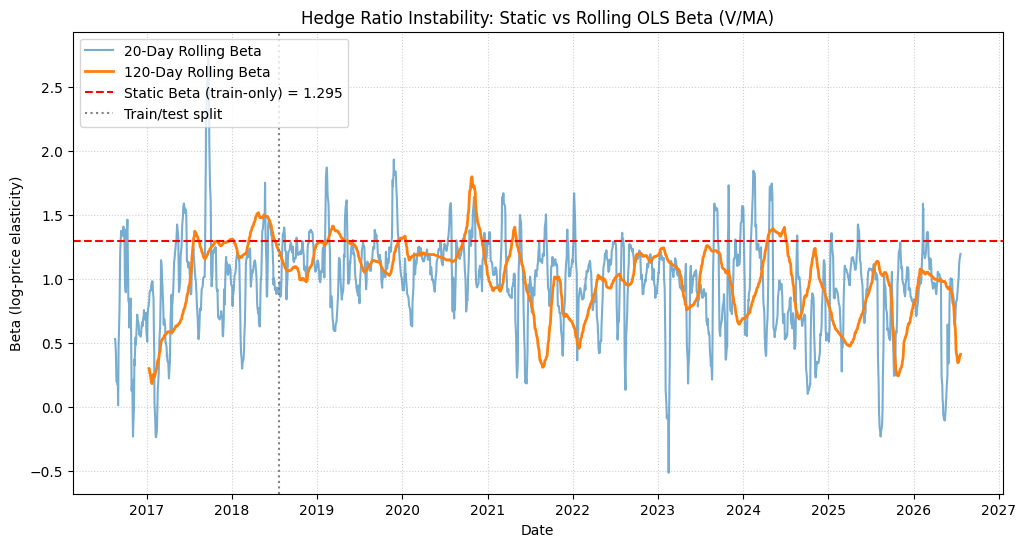

In [16]:
SPLIT = int(len(log_prices) * 0.20)
train_x, train_y = lx.iloc[:SPLIT], ly.iloc[:SPLIT]
test_x,  test_y  = lx.iloc[SPLIT:], ly.iloc[SPLIT:]

static_beta, static_alpha = fit_static_ols(train_x, train_y)
train_spread = train_y - static_beta * train_x - static_alpha
static_mu, static_sigma = train_spread.mean(), train_spread.std()

print(f"Train: {lx.index[0].date()} → {lx.index[SPLIT-1].date()}  ({SPLIT} days)")
print(f"Test:  {lx.index[SPLIT].date()} → {lx.index[-1].date()}  ({len(lx)-SPLIT} days)")
print(f"beta={static_beta:.4f}  alpha={static_alpha:.4f}  mu={static_mu:.6f}  sigma={static_sigma:.6f}")

plt.figure(figsize=(12, 6))
plt.plot(roll_20.index,  roll_20["beta"],  label="20-Day Rolling Beta", alpha=0.6)
plt.plot(roll_120.index, roll_120["beta"], label="120-Day Rolling Beta", linewidth=2)
plt.axhline(static_beta, color="red", linestyle="--", label=f"Static Beta (train-only) = {static_beta:.3f}")
plt.axvline(lx.index[SPLIT], color="gray", linestyle=":", label="Train/test split")
plt.title(f"Hedge Ratio Instability: Static vs Rolling OLS Beta ({A}/{B})")
plt.xlabel("Date"); plt.ylabel("Beta (log-price elasticity)")
plt.legend(loc="upper left"); plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

### Cell 5: Signal Generator (State Machine)

##### The Problem:

When building a Finite State Machine, a common problem when failing to build memory in a model is whipsawing - where the z-score hovers around the entry threshold. This leads to a model without memory making many trades every day, consequentially racking up lots of transaction costs.

---

### The Math

At any trading day $t$, the model should occupy one of three state spaces as represented by the position $P_t$:

$$P_t \in \{-1, 0, 1\}$$

where:

* $P_t = -1$ is shorting the spread (expecting spread to decrease)
* $P_t = 1$ is longing the spread (expecting spread to increase)
* $P_t = 0$ is flat (out of market)

To create a signal generator that prevents whipsawing by building a safety buffer (memory) into our rules, we have to create a state transition matrix:

$$\text{If } P_{t-1} = 0: \quad P_t = \begin{cases} -1 & \text{if } z_t > 2.0 \\ 1 & \text{if } z_t < -2.0 \\ 0 & \text{otherwise} \end{cases}$$

$$\text{If } P_{t-1} = -1: \quad P_t = \begin{cases} 0 & \text{if } z_t \le 0.5 \\ -1 & \text{otherwise} \end{cases}$$

$$\text{If } P_{t-1} = 1: \quad P_t = \begin{cases} 0 & \text{if } z_t \ge -0.5 \\ 1 & \text{otherwise} \end{cases}$$

This matrix creates a dynamic state-tracking system with a built-in memory buffer, locking us into our trades until a true mean reversion actually occurs.

In [17]:
# Function to generate signals

def generate_signals(z_scores):
    current_state = 0
    positions = []
    for z in z_scores:
        # Flat
        if current_state == 0:
            if z > 2:
                current_state = -1
            elif z < -2:
                current_state = 1
            else:
                current_state = 0
        
        # Short
        elif current_state == -1:
            if z <= 0.5:
                current_state = 0
            else:
                current_state = -1

        # Long
        elif current_state == 1:
            if z >= -0.5:
                current_state = 0
            else:
                current_state = 1
        
        positions.append(current_state)
    return positions

# Static path: frozen train-set parameters applied to the test set.
static_spread = test_y - static_beta * test_x - static_alpha
static_z = (static_spread - static_mu) / static_sigma

# Rolling path: restrict to the same test window so the comparison is fair.
roll_test = roll_120.loc[roll_120.index >= lx.index[SPLIT]]

sig_static  = pd.Series(generate_signals(static_z), index=static_z.index)
sig_rolling = pd.Series(generate_signals(roll_test["z"]), index=roll_test.index)

print("Static signals:\n", sig_static.value_counts().to_string())
print("\nRolling signals:\n", sig_rolling.value_counts().to_string())

Static signals:
  1    1047
 0     944
-1      19

Rolling signals:
  0    1301
-1     357
 1     352


### Cell 6: Backtesting Engine

Up to this point, all trading signal generation has been theoretical. However, to explore the robustness of our models, it is necessary to transition into a simulated testing environment. The core objective of this phase is to test whether an adaptive model (Rolling OLS) outpaces a rigid, historical model (Static OLS) when subjected to roughly the last 80% of the dataset.

---

##### Methodology

To construct a realistic backtest, we must account for Execution Lag, ensuring that a signal generated at the close of day $t$ only dictates our position at the open of day $t+1$. 

The execution process follows a four-step sequence:
1. Calculate the first differences of log prices.
2. Condense those individual returns into a spread portfolio return (using our static and rolling hedge ratios).
3. Generate the final strategy returns by multiplying the spread returns by our 1-day shifted position signals.
4. Normalize by gross exposure. Long \$1 of Y and short \$|$\beta$| of X is (1 + |$\beta$|) dollars of position funded by \$1 of capital. Reporting the P&L on \$1 overstates return on capital by that factor and hides the leverage entirely.

We also report position changes and days evaluated. Days evaluated must be identical across both strategies. If it isn't, the two models were tested on different markets and the comparison is void. Position changes exist because the state machine's whole justification is reducing trade count, and a backtest with zero transaction costs cannot show that benefit. Sharpe here is computed against a zero risk-free rate, which overstates it at the cash yields prevailing over this sample.

---

##### Evaluation Metrics

To evaluate and compare the models, we track two primary metrics:
* Cumulative Return: The total compounded wealth generated over the backtest horizon.
* Sharpe Ratio: The annualized risk-adjusted return, measuring how much return the strategy generated per unit of daily volatility.

In [18]:
r_x = test_x.diff()
r_y = test_y.diff()

r_static_gross  = r_y - static_beta * r_x
r_rolling_gross = r_y.loc[roll_test.index] - roll_test["beta"] * r_x.loc[roll_test.index]

r_static  = r_static_gross  / (1 + abs(static_beta))
r_rolling = r_rolling_gross / (1 + roll_test["beta"].abs())

r_static_strategy  = sig_static.shift(1)  * r_static
r_rolling_strategy = sig_rolling.shift(1) * r_rolling

equity_static  = (1 + r_static_strategy.dropna()).cumprod()
equity_rolling = (1 + r_rolling_strategy.dropna()).cumprod()

def sharpe(r):
    r = r.dropna()
    return np.sqrt(252) * r.mean() / r.std()

def n_trades(sig):
    return int((sig.diff().fillna(0) != 0).sum())

print(f"{'':<28} | {'Static OLS':>12} | {'Rolling OLS':>12}")
print("-" * 58)
print(f"{'Cumulative return':<28} | {(equity_static.iloc[-1]-1)*100:>11.2f}% | {(equity_rolling.iloc[-1]-1)*100:>11.2f}%")
print(f"{'Annualized Sharpe':<28} | {sharpe(r_static_strategy):>12.2f} | {sharpe(r_rolling_strategy):>12.2f}")
print(f"{'Position changes':<28} | {n_trades(sig_static):>12d} | {n_trades(sig_rolling):>12d}")
print(f"{'Days evaluated':<28} | {len(equity_static):>12d} | {len(equity_rolling):>12d}")

                             |   Static OLS |  Rolling OLS
----------------------------------------------------------
Cumulative return            |        9.22% |       38.34%
Annualized Sharpe            |         0.28 |         0.99
Position changes             |           15 |           68
Days evaluated               |         2009 |         2009


### Results and Looking Forward

Both models delivered positive absolute returns on V/MA across the 2,010-day test split (+9.22% Static, +38.34% Rolling), posting annualized Sharpe ratios of 0.28 and 0.99 respectively. The rolling OLS baseline clearly outperformed the frozen static setup on this pair. Because V/MA was flagged by the rolling cointegration screen in notebook 01 (47.6% sub-0.05 coverage, including a continuous ~2-year cointegrated run), a structural relationship actually exists here for a dynamic hedge ratio to trade—unlike a completely un-cointegrated pair.

However, three specific caveats keep that 0.99 Sharpe honest before we treat it as an unassailable benchmark:

1. These returns are gross of execution costs. The Rolling model logged 68 position changes at 5 bps per entry/exit, execution drag subtracts roughly 0.7% from total return.
2. The Sharpe ratio is computed excess-of-zero. By factoring in prevailing risk-free cash yields, the net Sharpe return reduces.
3. Across ~2,000 test days, the standard error of a Sharpe ratio estimate is roughly 0.2. While a 0.99 Sharpe sits several standard errors away from zero, it carries a real margin of error. Any downstream model must be judged against this hurdle, not against zero.

#### Evaluating the Baselines
The Static model suffers from its rigidity. By fitting $\beta = 1.2948$ on the 20% training window (2016–2018) and freezing it, the model assumes an unchanging relationship. That frozen $\beta$ sits at the upper edge of the static table across other windows (which range from 0.68 to 1.17). Because V/MA is fundamentally cointegrated, the spread still behaved like a spread, preventing the strategy from completely breaking down, but sticking to a stale hedge ratio left substantial returns on the table as the relationship drifted.

On the other hand, the Rolling model's limitations come from information lag and window choice:
- Because a rolling regression relies on backward-looking data, it only adapts to parameter drift after a regime shift has already occurred. This causes the model to enter trades late or hold onto positions after the local relationship has broken.
- The 120-day lookback window is inherently arbitrary. It remains too slow for abrupt market shocks while remaining oversensitive to short-term noise. 

The strategy traded at a reasonable frequency—68 position changes across 2,009 days (~1 trade every 30 days) with no signs of whipsawing — but every single trade was executed by looking backwards.

#### Next Steps
To overcome these OLS limitations, we must move toward dynamic state-space modeling. The next step is implementing a Linear Kalman Filter, which enables continuous, real-time parameter tracking without relying on arbitrary lookback windows or lagging regressions.

#### Phase 2 Summary
This notebook proves three things: $\beta$ drifts over time, a rolling estimator successfully adapts to that drift to beat a frozen baseline on V/MA, and a cointegrated pair is tradeable even with a simple dynamic hedge ratio. 

It does not prove that a Kalman Filter or an HMM regime gate will automatically beat this baseline. A Sharpe ratio near 1.0 sets a high bar, and beating it net of transaction costs is the core question the remaining notebooks must answer.